# The Gaussian normal distribution

## Approximating the binomial distribution

Consider a sequence of Bernoulli distributed random variables $X_i$ with the same parameter $p$, and let $S_n := \sum_{i=1}^n X_i$ be the sum of the first $n$ of them. From the chapter [The most important discrete distributions](important-discrete-distributions.ipynb) we already know that $S_n \sim \operatorname{Bin}(n,p)$, that is, that this sum is binomially distributed. A reminder: this means that the pmf of $S_n$ is $p(k) = \binom{n}{k}p^k(1-p)^{n-k}$.

For the concrete values $n=100,\ p=0.4$, a histogram of $100000$ samples looks roughly like this:


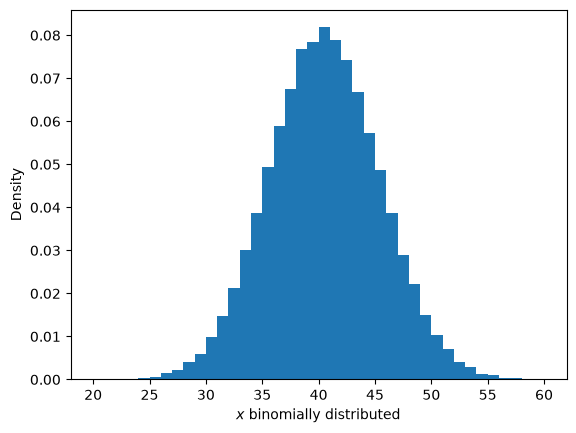

In [1]:
import numpy as np
from scipy.stats import binom, norm
from matplotlib import pyplot as plt
np.random.seed(123123)
binom_samples = binom.rvs(n=100,
                          p=0.4,
                          size=100000)
plt.hist(binom_samples, bins=40, density=True)
plt.xlabel("$x$ binomially distributed")
plt.ylabel("Density")
plt.show()

Since this shape always comes out like this for large samples, whatever $p$ may be (try it out!), one might imagine that the distribution can be approximated with the help of a function that is easier to compute than binomial coefficients $\binom{n}{k} = \frac{n!}{k!(n-k)!}$.

**Aside**: there is in fact also *Stirling's formula* for approximating the factorial

$$
n! \approx \sqrt{2\pi n} {\left(\frac{n}{e}\right)}^n
$$

which for binomial coefficients directly gives us: $\binom{n}{k} \approx \frac{\sqrt{n}}{\sqrt{2\pi}\sqrt{k}\sqrt{n-k} }  \frac{n^n}{k^k {\left(n-k\right)}^{(n-k)} }$

With this an approximation can now be proved (even if it is not entirely easy):

$$
P(S_n = k) = \binom{n}{k}p^k(1-p)^{n-k} \sim
\frac{1}{\sqrt{np(1-p)}} \frac{1}{\sqrt{2\pi}} e^{-\frac{x^2}{2}} \quad \text{ for } n \to \infty
$$

where for $x$ on the right-hand side the sequence $x=x_n$ with
$x_n = x_n(k) = \frac{k-np}{\sqrt{np(1-p)}}$ has to be substituted. The symbol $\sim$ means: asymptotically equal, i.e. the quotient converges to $1$.

This approximation is helpful in that we can now tabulate the function $e^{-\frac{x^2}{2}}$ and read off concrete values for given $n,p$. That is considerably more efficient than computing binomial coefficients. The whole observation is also known as the **theorem** of de Moivre–Laplace, and for now it will serve us as motivation for examining the function $e^{-\frac{x^2}{2}}$ more closely.

## An integral

To turn the function $e^{-\frac{x^2}{2}}$ into a probability density, the integral has to come out as $1$. Because it will be very useful afterwards, we compute a somewhat more general integral right away:

:::{admonition} Lemma
Let $v \in \mathbb{R}$ with $v > 0$. Then

$$
\int_{-\infty}^\infty e^{-\frac{x^2}{2v}} dx = \sqrt{2\pi v}.
$$
:::

:::{admonition} Proof
Since there is a square root on the right-hand side, squaring both sides of the equation suggests itself. We then keep rewriting the left-hand side until we can transform an integral over $\mathbb{R}^2$ into polar coordinates and, after a substitution, easily find antiderivatives:

$$
\begin{aligned}
  & {\left( \int_{-\infty}^\infty e^{-\frac{x^2}{2v}} dx \right)}^2 \\
 =& {\left( \int_{-\infty}^\infty e^{-\frac{x^2}{2v}} dx \right)}{\left( \int_{-\infty}^\infty e^{-\frac{y^2}{2v}} dy \right)} \\
 =& \int_{-\infty}^\infty e^{-\frac{x^2}{2v}} {\left( \int_{-\infty}^\infty e^{-\frac{y^2}{2v}} dy \right)} dx \\
 =& \int_{-\infty}^\infty {\left( \int_{-\infty}^\infty e^{-\frac{x^2}{2v}} e^{-\frac{y^2}{2v}} dy \right)} dx \\
 =& \int_{-\infty}^\infty {\left( \int_{-\infty}^\infty e^{-\frac{x^2+y^2}{2v}} dy \right)} dx \\
 =& \int_{\mathbb{R}^2} e^{-\frac{x^2+y^2}{2v}} d(x,y) \\
 =& \int_{0}^\infty \int_{0}^{2\pi} r e^{-\frac{r^2}{2v}} d\phi dr \\
 =& \int_{0}^\infty r e^{-\frac{r^2}{2v}}  \int_{0}^{2\pi} d\phi dr \\
 =& \int_{0}^\infty r e^{-\frac{r^2}{2v}} [\phi]_0^{2\pi} dr \\
 =& \int_{0}^\infty r e^{-\frac{r^2}{2v}} 2\pi dr \\
 =& 2\pi \int_{0}^\infty e^{-\frac{r^2}{2v}} r dr \\
 =& 2\pi \int_{0}^{-\infty} e^u (-v)du \\
 =& 2\pi v \int_{-\infty}^{0} e^u du \\
 =& 2\pi v [e^u]_{-\infty}^{0} \\
 =& 2\pi v.
\end{aligned}
$$
:::

Since integrals turn up rather often in statistics, it is not a bad idea to work out, for this calculation, exactly what happens at each step and why.

## The one-dimensional normal distribution

:::{admonition} Definition
Let $\mu,\sigma \in \mathbb{R}$ with $\sigma > 0$. Then the distribution with density function

$$
\phi(x) = \phi(x,\mu,\sigma) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

is called the *normal distribution*, and for a real random variable $X$ with this distribution we also write $X \sim \mathcal{N}(\mu,\sigma^2)$.
:::

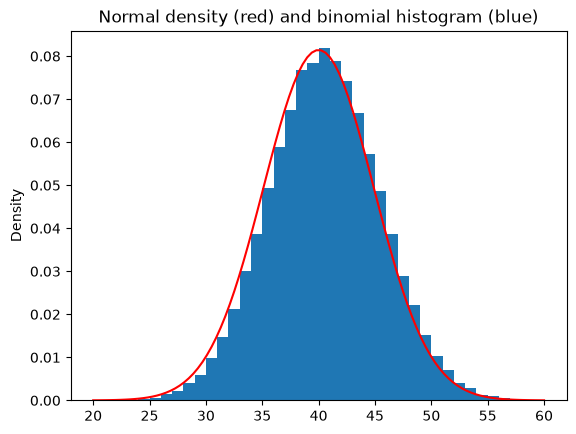

In [2]:
x = np.linspace(20,60,100)
plt.hist(binom_samples, bins=40, density=True)
plt.plot(x, norm(loc=40, scale=np.sqrt(24)).pdf(x), color="red")   # expected value n p = 40, variance n p (1-p) = 24
plt.ylabel('Density')
plt.title('Normal density (red) and binomial histogram (blue)')
plt.show()

:::{admonition} Proposition
If $X \sim \mathcal{N}(\mu,\sigma^2)$, then $\mathbb{E}(X) = \mu$ and $\mathbb{V}(X) = \sigma^2$.
:::

:::{admonition} Proof
We substitute the density for $X$ into the formula for $\mathbb{E}(X)$ and transform the integral over $x$ into an integral over $x + \mu$:

$$
\begin{aligned}
\mathbb{E}(X) &= \int_{-\infty}^{\infty} x\phi(x) dx \\
              &=  \int_{-\infty}^{\infty} x \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}} dx \\
              &= \frac{1}{\sigma\sqrt{2\pi}} \int_{-\infty}^{\infty} x e^{-\frac{(x-\mu)^2}{2\sigma^2}} dx \\
              &= \frac{1}{\sigma\sqrt{2\pi}} \int_{-\infty}^{\infty} (x+\mu) e^{-\frac{x^2}{2\sigma^2}} dx \\
              &= \frac{1}{\sigma\sqrt{2\pi}} \left( \left( \int_{-\infty}^{\infty} x e^{-\frac{x^2}{2\sigma^2}} dx \right) + \mu \left( \int_{-\infty}^{\infty} e^{-\frac{x^2}{2\sigma^2}} dx \right) \right) \\
              &= \frac{1}{\sigma\sqrt{2\pi}} \left( \left( \int_{-\infty}^{\infty} x e^{-\frac{x^2}{2\sigma^2}} dx \right) + \mu \sigma\sqrt{2\pi} \right) \\
              &= \mu + \frac{1}{\sigma\sqrt{2\pi}} \left( \int_{-\infty}^{\infty} x e^{-\frac{x^2}{2\sigma^2}} dx \right) = \mu.\\
\end{aligned}
$$

The expression after the $\mu +$ is simply $0$, because the function has point symmetry about $0$ (the factor $x$ is obviously an odd function, and the other factor depends only on $|x|$).

The variance can be dealt with in exactly the same way, by simplifying this expression:

$$
\begin{aligned}
\mathbb{V}(X) &= \int_{-\infty}^{\infty} x^2\phi(x) dx  - {\left( \mathbb{E}(X) \right)}^2 \\
              &= \int_{-\infty}^{\infty} x^2\frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}} dx - \mu^2.
\end{aligned}
$$

After the same substitution $x \to x + \mu$ and expanding $(x+\mu)^2$, what is left is $\frac{1}{\sigma\sqrt{2\pi}} \int x^2 e^{-x^2/2\sigma^2}\,dx$ (the mixed term is again odd, and the $\mu^2$ term cancels), and integration by parts with $u = x$, $v' = x e^{-x^2/2\sigma^2}$ yields $\sigma^2$ for it; the details we leave to you.
:::

:::{admonition} Definition
A random variable with $X \sim \mathcal{N}(0,1)$ is also called *standard normally distributed*
:::

:::{admonition} Proposition
If $X \sim \mathcal{N}(\mu,\sigma^2)$, then $\frac{X - \mu}{\sigma} \sim \mathcal{N}(0,1)$.
:::


:::{admonition} Proof
**Idea:**
It is immediately clear that $\mathbb{E}(X-\mu) = 0$ and that $\mathbb{V}\left(\frac{X-\mu}{\sigma}\right) = 1$.
Less clear is that the new random variable really is normally distributed. That can be proved, for instance, with the moment generating function.
:::

Standardisation is a special case of a more general statement that one needs all the time:

:::{admonition} Proposition
If $X \sim \mathcal{N}(\mu,\sigma^2)$ and $a \neq 0$, $b \in \mathbb{R}$, then

$$
aX + b \sim \mathcal{N}\left( a\mu + b,\ a^2\sigma^2 \right).
$$

So normality is preserved under affine-linear transformations.
:::

:::{admonition} Proof
**Idea:** The expected value and the variance follow from the rules of calculation of the chapter [Expected value and variance](expectation-variance.md). That the shape is preserved can be seen from the density: for a random variable $X$ with density $p_X$, $Y = aX+b$ has the density

$$
p_Y(y) = \dfrac{1}{|a|}\, p_X\!\left( \dfrac{y-b}{a} \right)
$$

(the transformation formula: the factor $\frac{1}{|a|}$ makes sure that the integral comes out as $1$ again). Substituting the normal density here, the exponent reads $-\frac{((y-b)/a - \mu)^2}{2\sigma^2} = -\frac{(y - (a\mu+b))^2}{2a^2\sigma^2}$, and the prefactor becomes $\frac{1}{|a|\sigma\sqrt{2\pi}}$ – which is exactly the density of $\mathcal{N}(a\mu+b, a^2\sigma^2)$.
:::

Two special cases are worth remembering. With $a = \frac1\sigma$ and $b = -\frac\mu\sigma$ one obtains the standardisation from above. And conversely: if $Z \sim \mathcal{N}(0,1)$, then $\sigma Z + \mu \sim \mathcal{N}(\mu,\sigma^2)$ – so every normal distribution arises from the standard normal distribution by stretching and shifting. That is also exactly how they are generated on a computer: `mu + sigma * rng.standard_normal(n)` needs only a single random number generator for all normal distributions. In the chapter [The multivariate normal distribution](multivariate-normal.ipynb) this is the starting point: there the same construction is carried out with a matrix instead of a number.

We also make use of the fact that the sum of independent random variables with densities $f,g$ itself has a density again, namely the *convolution* $f \ast g$. Instead of introducing and proving that rigorously, we merely record the result for normal distributions, which can be verified with the convolution.

:::{admonition} Theorem
Among all **continuous** distributions of real random variables $X$ with **support all of $\mathbb{R}$** and fixed expected value $\mu = \mathbb{E}(X)$ and fixed variance $\sigma^2 = \mathbb{V}(X)$, the normal distribution is the one with maximal entropy.
:::

To be able to state this theorem precisely at all, we need a notion of entropy for continuous distributions. Instead of doing that now, we shall turn to it later, when we also discuss relative entropy, its continuous version and likelihood.

:::{admonition} Proposition
If $X \sim \mathcal{N}(\mu_1, \sigma_1^2)$ and $Y \sim \mathcal{N}(\mu_2, \sigma_2^2)$ are independent, then $X + Y \sim \mathcal{N}(\mu_1 + \mu_2,\ \sigma_1^2 + \sigma_2^2)$. More generally, every linear combination $aX + bY$ is again normally distributed, with expected value $a\mu_1 + b\mu_2$ and variance $a^2\sigma_1^2 + b^2\sigma_2^2$.

**Without proof**
:::

The expected value and the variance follow from the rules of calculation in the chapter [Expected value and variance](expectation-variance.md); what is remarkable is that the *shape* is preserved too – the sum is not just some distribution with these moments, but a bell curve again. That is by no means self-evident: the sum of two uniformly distributed variables is triangularly distributed, not uniformly distributed. One says that the normal distribution is *stable under convolution*. In the chapter on the [multivariate normal distribution](multivariate-normal.ipynb) we see the generalisation: there the same holds for *dependent* $X, Y$ as well, as soon as they are jointly normally distributed, with an additional covariance term in the variance.

What matters, though, is the theorem's take-home message: if nothing is known about a continuous distribution of real numbers beyond its expected value and variance, then the corresponding normal distribution is the most sensible assumption. In this sense the normal distribution is a good continuous substitute for the discrete uniform distribution, but now on all of $\mathbb{R}$ (the normal distribution has support $\mathbb{R}$).

The restriction to support $\mathbb{R}$ is not a formality here but the actual modelling assumption. If the support is known more precisely, a different distribution is the one with maximal entropy – and hence the most sensible assumption:

| Support | what else is known | distribution with maximal entropy |
|---|---|---|
| $\{1,\dots,n\}$ | nothing | discrete uniform distribution, $p(k) = \frac1n$ |
| $[a,b]$ | nothing | continuous uniform distribution, $f(x) = \frac{1}{b-a}$ |
| $[0,\infty)$ | expected value $\mu$ | exponential distribution, $f(x) = \lambda e^{-\lambda x}$ with $\lambda = \frac1\mu$ |
| $\mathbb{R}$ | expected value and variance | normal distribution |
| $[a,b]$ | expected value and variance | truncated normal distribution (`scipy.stats.truncnorm`) |

The profiles of the three continuous distributions are in the chapter [The most important continuous distributions](important-continuous-distributions.ipynb), the discrete uniform distribution in the chapter [The most important discrete distributions](important-discrete-distributions.ipynb). The truncated normal distribution is exactly what it sounds like: a normal distribution whose density is set to $0$ outside $[a,b]$ and renormalised inside. You need it when a quantity is bounded by its very nature – proportions between $0$ and $1$, readings at the display limit of an instrument – and a normal model would otherwise spread probability mass where there can be no values at all.

The pattern behind it is always the same: maximal entropy means "assume as little in addition as possible". What you know goes in as a constraint; everything else you leave to chance.


## The central limit theorem

:::{admonition} Theorem
If $X_i$ is a sequence of identically distributed, mutually independent (iid = independent identically distributed) random variables with expected value $\mathbb{E}(X_i)=0$ and variance $\mathbb{V}(X_i)=\sigma^2$,
and we consider the scaled sum $Z_N := \dfrac{1}{\sigma\sqrt{N}} \sum_{i=1}^N X_i$ (with $\mathbb{E}(Z_N)=0$ and $\mathbb{V}(Z_N)=1$), then we have convergence in distribution:

$$
Z_N \xrightarrow{N \to \infty} \mathcal{N}(0,1)
$$
:::

The letter $Z$ is meant to remind you that $Z_N$ is the version of the sum $S_N = \sum_{i=1}^N X_i$, which we looked at above for Bernoulli variables, normalised to expected value $0$ and variance $1$.

Convergence in distribution means that the cumulative distribution function of $Z_N$ converges to the cumulative distribution function of a standard normal distribution.

There are also weakened versions of this theorem, which allow certain dependencies among the $X_i$.

:::{admonition} Remark
The theorem matters to us because it allows a sum of independent random variables to be approximated by a normal distribution. This happens often in practice when you take measurements on physical or techno-social systems, which are as a rule affected by a long list of largely independent disturbances. This sum of sources of error is (for a sufficiently large number of independent sources of error) approximately normally distributed.
:::

To give two concrete examples: the error in position fixing with GNSS systems such as GPS is normally distributed (even though the atmospheric disturbances that make the value less accurate are not normally distributed). In the industrial manufacture of components there are likewise sources of error throughout the production process that add up to a normal distribution in the end – whose variance has to be kept small enough for the component to do its job. A Lego brick, for instance, must not deviate too much from an identically built Lego brick, or the structure will not hold together properly afterwards.

:::{admonition} Remark
**The standard error.** The most important application for us: the mean $\overline{X}_N$ of a sample of size $N$ is itself a (scaled) sum, and hence approximately normally distributed for large $N$, with expected value $\mu$ and standard deviation $\sigma/\sqrt{N}$. This standard deviation of the sample mean is called the **standard error**. Since a normally distributed quantity deviates from its expected value by less than $1.96$ standard deviations with probability $95\,\%$, the true expected value lies in the interval $\overline{X}_N \pm 1.96\,\sigma/\sqrt{N}$ for about $95\,\%$ of all samples. That is sharper than Chebyshev's inequality from the chapter [Expected value and variance](expectation-variance.md), which guarantees only $75\,\%$ for two standard errors, and it is the recipe with which the chapter [Statistical tests](statistical-tests.md) infers from the sample to the population. Titanic example: of $314$ women, $74.2\,\%$ survived; the standard error of this proportion is $\sqrt{0.742 \cdot 0.258 / 314} \approx 0.025$, so the interval is about $74 \pm 5$ percentage points.
:::


**Aside**: one can also estimate the speed of the convergence, and so find out how good the approximation by a normal distribution is:

:::{admonition} Theorem (Berry–Esseen)
There exists a constant $C$ with $0.41 \le C \le 0.48$ and the following property:

If $X_i$ is a sequence of iid random variables with expected value $0$ and variance $\sigma^2$, and the third absolute moments $\mathbb{E}|X_i|^3 = \rho < \infty$ exist as well, and if we write $F_N$ for the cumulative distribution function of $Z_N = \frac{1}{\sigma\sqrt{N}} \sum_{i=1}^N X_i$ and $\Phi$ for the cumulative distribution function of the standard normal distribution $\mathcal{N}(0,1)$, then for all $N$:

$$
\sup_{x \in \mathbb{R}} \left| F_N(x) - \Phi(x) \right| \ \leq\ \dfrac{C\rho}{\sigma^3 \sqrt{N}}.
$$
:::

The exact value of $C$ is not known; the bounds given are the current state of research. So for concretely known $\sigma,\rho$ we can always determine an $N$ that makes the left-hand side as small as we like. In other words: for any accuracy desired, it can be computed how many of the iid random variables have to be added up (scaled) in order to approximate $Z_N$ by a standard normal distribution.

Of course: if the expected value is not $0$, a variant can be proved as a corollary (as with the central limit theorem), so that the convergence is to $\mathcal{N}(\mu,1)$. With a different rescaling, to $\mathcal{N}(\mu,\sigma^2)$ as well. In practice it looks more like this: all unknown error terms are modelled with a normal distribution whose expected value and variance are estimated empirically.

## A practical example: The "$N \ge 30$" myth

In many textbooks, statistics courses and analysis protocols you find a rule of thumb: *from $N = 30$ on you may work with a normal distribution.* This rule is so widespread that it is rarely questioned – and in that form it is wrong. Berry–Esseen also tells us why.

The bound above reads $\frac{C\rho}{\sigma^3\sqrt{N}}$. In it, $N$ appears only under a square root; what is decisive is the factor $\rho/\sigma^3$: the third absolute moment relative to the third power of the standard deviation, that is, a measure of how skewed the individual random variable is. For a symmetric distribution this factor is small; for a skewed one it can become arbitrarily large – and then $N = 30$ is simply not enough.

The most important case in practice is a binary feature: "side effect occurred yes/no", "click yes/no", "survived yes/no". Such a feature is Bernoulli distributed with parameter $p$, and we can compute the factor. For $X \sim \operatorname{Bernoulli}(p)$, centred on expected value $0$,

$$
\sigma^2 = p(1-p), \qquad \rho = \mathbb{E}\left|X - p\right|^3 = p(1-p)\left[(1-p)^2 + p^2\right],
$$

hence

$$
\dfrac{\rho}{\sigma^3} = \dfrac{(1-p)^2 + p^2}{\sqrt{p(1-p)}}.
$$

For a balanced feature, $p = 0.5$, this is exactly $1$, and the Berry–Esseen bound at $N = 30$ comes out (with $C \approx 0.44$) at $0.44/\sqrt{30} \approx 0.08$. So the cumulative distribution functions differ by at most eight percentage points – usable. For a rare event, $p = 0.01$, by contrast, the same factor is $\approx 9.85$, and the bound at $N = 30$ becomes

$$
\dfrac{0.44 \cdot 9.85}{\sqrt{30}} \approx 0.79.
$$

A bound of $0.79$ on a deviation between two cumulative distribution functions that both lie between $0$ and $1$ is no longer a statement – it is useless. Only at $N = 1000$ does it fall to $\approx 0.14$. (The Berry–Esseen bound is an *upper* bound; the actual error can be smaller. But a rule of thumb that cannot even be justified from above is one you should not use.)

:::{admonition} Rule of thumb
**The Laplace condition.** The binomial distribution $\operatorname{Bin}(N,p)$ may be approximated by a normal distribution if

$$
N p \ge 10 \qquad \text{and} \qquad N(1-p) \ge 10,
$$

that is, if *both* outcomes occur at least ten times on average. For $p = 0.5$ that means $N \ge 20$, but for $p = 0.01$ it means $N \ge 1000$. Some textbooks write $Np(1-p) \ge 9$ instead; that comes to the same thing.
:::

So the difference from the $N \ge 30$ rule is not academic: for an event that hits one case in a hundred, the correct threshold is higher by a factor of $33$. That is exactly the situation with rare side effects in medical studies.

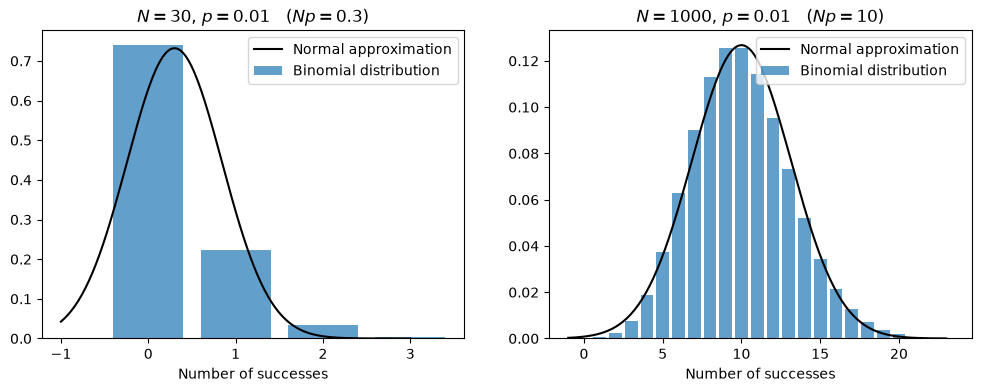

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for ax, n in ((ax1, 30), (ax2, 1000)):
    p = 0.01
    k = np.arange(0, int(n * p + 4 * np.sqrt(n * p * (1 - p))) + 2)
    ax.bar(k, binom(n, p).pmf(k), label="Binomial distribution", alpha=0.7)
    xs = np.linspace(k.min() - 1, k.max(), 200)
    ax.plot(xs, norm(loc=n * p, scale=np.sqrt(n * p * (1 - p))).pdf(xs),
            color="black", label="Normal approximation")
    np_text = f"{n * p:g}"
    ax.set_title(f"$N = {n}$, $p = 0.01$   ($Np = {np_text}$)")
    ax.set_xlabel("Number of successes")
    ax.legend()

plt.show()

On the left, at $N = 30$, almost the whole probability mass sits on the values $0$ and $1$ – the distribution is cut off at zero and heavily skewed to the right, while the normal approximation runs placidly off into the negatives and spreads probability where there are no outcomes at all. On the right, at $N = 1000$, the Laplace condition is just satisfied, with $Np = 10$, and the bell shape is recognisable.

The moral is more general than the example: a rule of thumb that names only the sample size and says nothing about the distribution cannot work. What counts is the ratio of skewness to sample size.